In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)

In [2]:
df_heart = pd.read_csv(r"D:\archive\Heart_failure_clinical_records_dataset.csv")
df_bank = pd.read_csv(r"D:\archive (1)\data_banknote_authentication.csv")

print(df_heart.shape, list(df_heart.columns))
print(df_bank.shape, list(df_bank.columns))
display(df_heart.head())
display(df_bank.head())

(299, 13) ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'DEATH_EVENT']
(1372, 5) ['Variance_Wavelet', 'Skewness_Wavelet', 'Curtosis_Wavelet', 'Image_Entropy', 'Class']


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


,Variance_Wavelet,Skewness_Wavelet,Curtosis_Wavelet,Image_Entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


0 nulls in heart
0 nulls in banknote


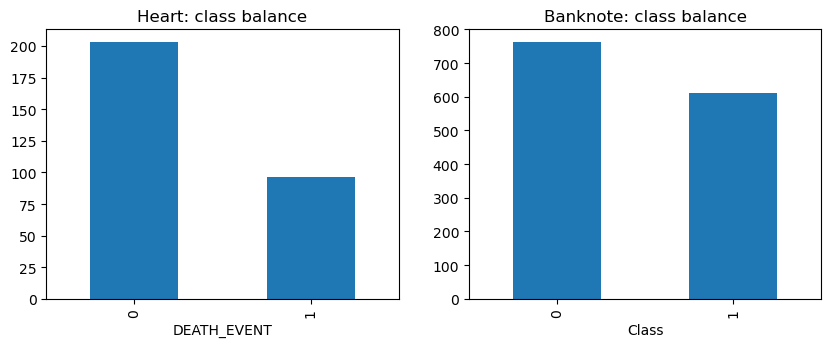

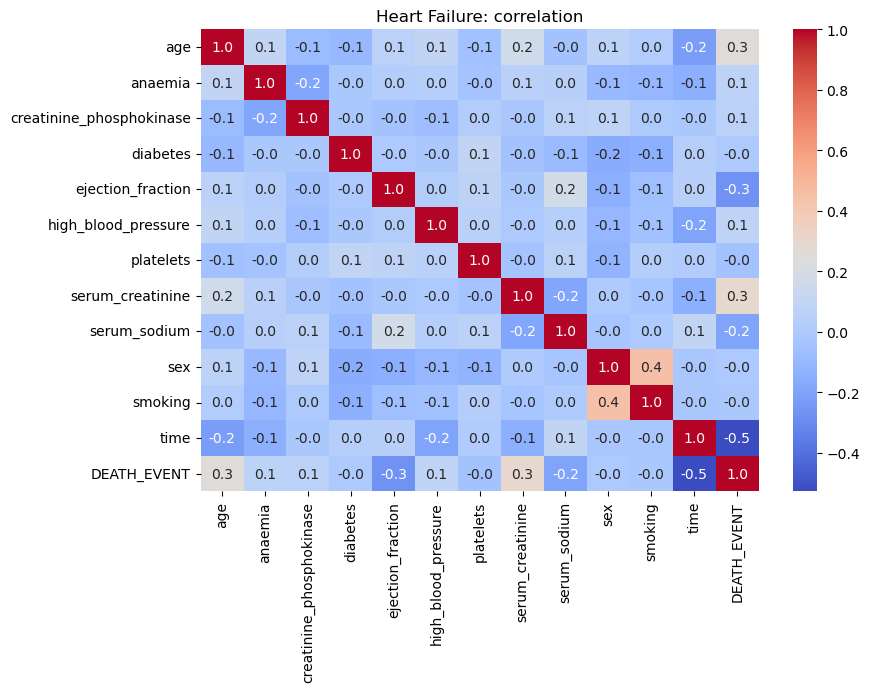

In [4]:
print(df_heart.isnull().sum().sum(), "nulls in heart")
print(df_bank.isnull().sum().sum(), "nulls in banknote")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df_heart["DEATH_EVENT"].value_counts().plot.bar(ax=ax[0], title="Heart: class balance")
df_bank["Class"].value_counts().plot.bar(ax=ax[1], title="Banknote: class balance")
plt.show()

plt.figure(figsize=(9, 6))
sns.heatmap(df_heart.corr(), annot=True, fmt=".1f", cmap="coolwarm")
plt.title("Heart Failure: correlation")
plt.show()

In [5]:
DATASETS = {
    "heart": {
        "title": "Heart Failure Prediction",
        "df": df_heart, "target": "DEATH_EVENT",
        "labels": {0: "Survived", 1: "Death"},
    },
    "bank": {
        "title": "Banknote Authentication",
        "df": df_bank, "target": "Class",
        "labels": {0: "Genuine", 1: "Forged"},
    },
}

In [6]:
def train_and_evaluate(key):
    cfg = DATASETS[key]
    df = cfg["df"].copy()

    X = df.drop(columns=cfg["target"])
    y = df[cfg["target"]]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y)

    pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000)),
    ])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    print("=" * 50, "\n", cfg["title"].upper(), "\n", "=" * 50)
    print(f"Train: {len(X_train)} | Test: {len(X_test)}")
    print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred):.4f}")
    print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
    print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}\n")
    print(classification_report(y_test, y_pred, target_names=list(cfg["labels"].values())))

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=ax[0],
                xticklabels=cfg["labels"].values(), yticklabels=cfg["labels"].values())
    ax[0].set(title="Confusion Matrix", xlabel="Predicted", ylabel="Actual")

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
    ax[1].plot([0, 1], [0, 1], "--", color="gray")
    ax[1].set(title="ROC Curve", xlabel="False Positive Rate", ylabel="True Positive Rate")
    ax[1].legend()

    coefs = pd.Series(pipe.named_steps["clf"].coef_[0], index=X.columns).sort_values()
    coefs.plot.barh(ax=ax[2], color=np.where(coefs > 0, "tab:red", "tab:blue"))
    ax[2].set(title="Feature Coefficients (scaled)")
    plt.tight_layout()
    plt.show()

    cfg["pipe"] = pipe
    cfg["features"] = list(X.columns)
    cfg["defaults"] = X.median().round(3).to_dict()
    cfg["metrics"] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }

 HEART FAILURE PREDICTION 
Train: 239 | Test: 60
Accuracy : 0.8167
Precision: 0.7857
Recall   : 0.5789
F1-score : 0.6667
ROC-AUC  : 0.8588

              precision    recall  f1-score   support

    Survived       0.83      0.93      0.87        41
       Death       0.79      0.58      0.67        19

    accuracy                           0.82        60
   macro avg       0.81      0.75      0.77        60
weighted avg       0.81      0.82      0.81        60



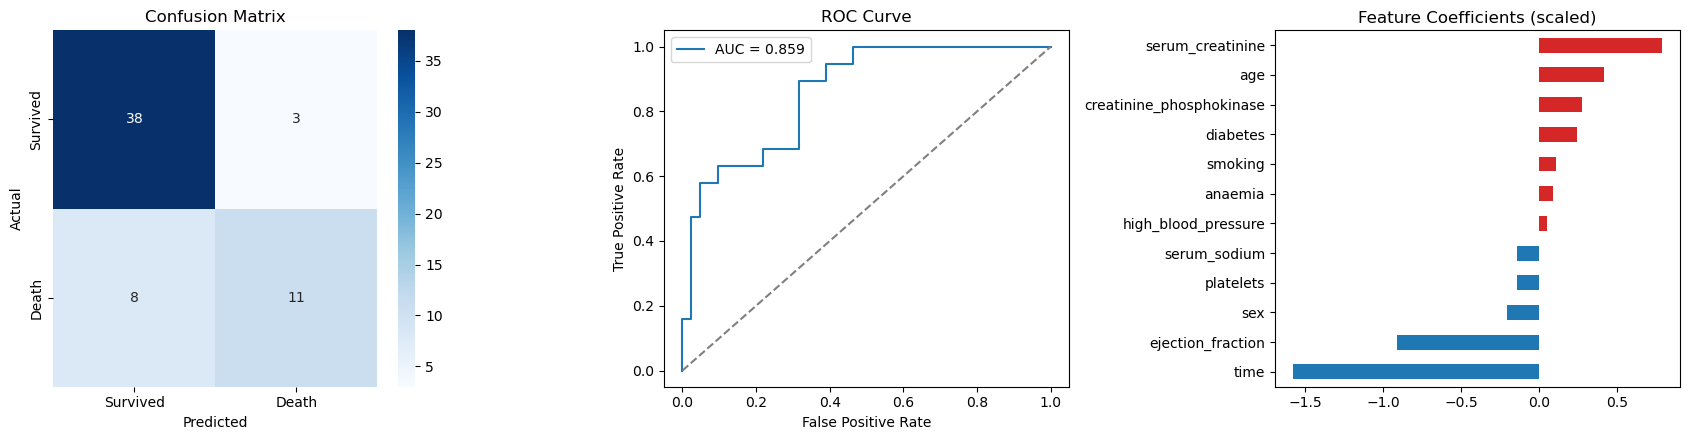

 BANKNOTE AUTHENTICATION 
Train: 1097 | Test: 275
Accuracy : 0.9709
Precision: 0.9385
Recall   : 1.0000
F1-score : 0.9683
ROC-AUC  : 0.9999

              precision    recall  f1-score   support

     Genuine       1.00      0.95      0.97       153
      Forged       0.94      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275



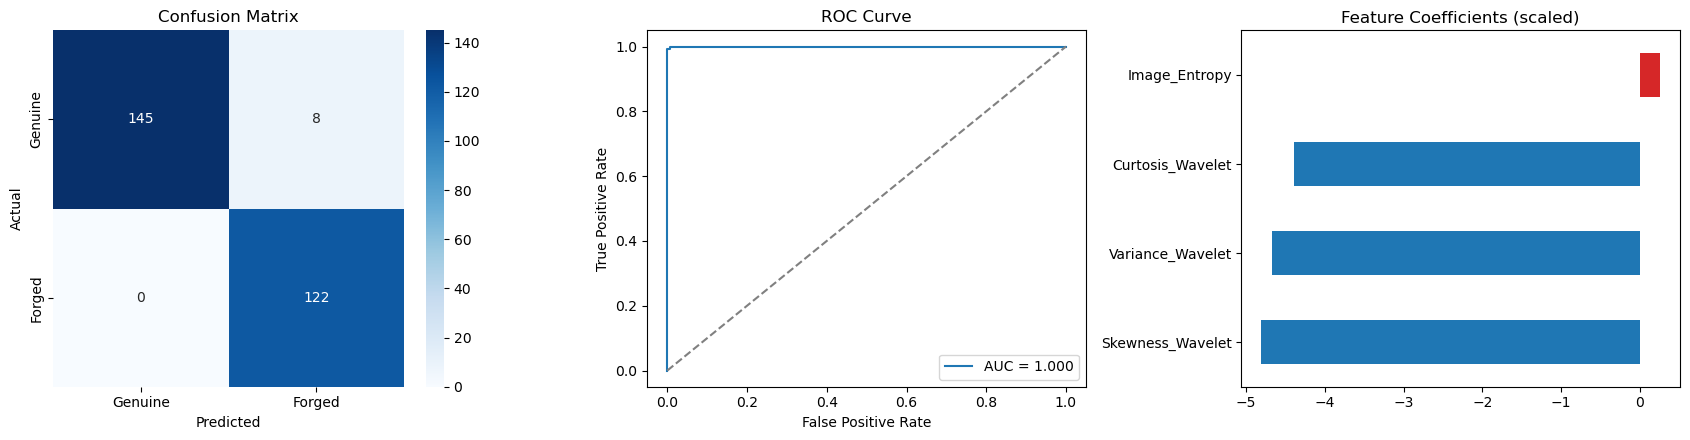

,Accuracy,Precision,Recall,F1,ROC-AUC
Heart Failure Prediction,0.8167,0.7857,0.5789,0.6667,0.8588
Banknote Authentication,0.9709,0.9385,1.0000,0.9683,0.9999


In [7]:
train_and_evaluate("heart")
train_and_evaluate("bank")

summary = pd.DataFrame({c["title"]: c["metrics"] for c in DATASETS.values()}).T.round(4)
display(summary)

In [8]:
def predict(key, values):
    cfg = DATASETS[key]
    X = pd.DataFrame([values], columns=cfg["features"])
    p = float(cfg["pipe"].predict_proba(X)[0, 1])
    return cfg["labels"][int(p >= 0.5)], p

for k, c in DATASETS.items():
    print(k, "->", predict(k, [c["defaults"][f] for f in c["features"]]))

heart -> ('Survived', 0.1204246072321096)
bank -> ('Genuine', 0.2807691260922539)


In [12]:
import os
os.makedirs(r"D:\pip_temp", exist_ok=True)
os.environ["TMP"] = r"D:\pip_temp"
os.environ["TEMP"] = r"D:\pip_temp"

!pip install --no-cache-dir gradio

   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.4 MB ? eta -:--:--
    --------------------------------------- 0.5/31.4 MB 1.0 MB/s eta 0:00:30
   - -------------------------------------- 0.8/31.4 MB 1.1 MB/s eta 0:00:29
   - -------------------------------------- 1.0/31.4 MB 1.0 MB/s eta 0:00:30
   - -------------------------------------- 1.3/31.4 MB 1.0 MB/s eta 0:00:30
   -- ------------------------------------- 1.6/31.4 MB 1.1 MB/s eta 0:00:28
   -- ------------------------------------- 1.8/31.4 MB 1.1 MB/s eta 0:00:27
   -- ------------------------------------- 1.8/31.4 MB 1.1 MB/s eta 0:00:27
   -- ------------------------------------- 2.1/31.4 MB 994.4 kB/s eta 0:00:30
   -- ------------------------------------- 2.1/31.4 MB 994.4 kB/s eta 0:00:30
   --- ----------------

In [13]:
import gradio as gr

def build_tab(key):
    cfg = DATASETS[key]
    gr.Markdown(f"### {cfg['title']}")
    inputs = [gr.Number(label=f, value=cfg["defaults"][f]) for f in cfg["features"]]
    btn = gr.Button("Predict", variant="primary")
    out_label = gr.Textbox(label="Prediction")
    out_prob = gr.Label(label="Probability")

    def run(*vals):
        label, p = predict(key, list(vals))
        return label, {cfg["labels"][1]: p, cfg["labels"][0]: 1 - p}

    btn.click(run, inputs, [out_label, out_prob])

with gr.Blocks(title="Logistic Regression Classifier") as demo:
    gr.Markdown("# Logistic Regression: Two Datasets")
    for k, c in DATASETS.items():
        with gr.Tab(c["title"]):
            build_tab(k)

demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [14]:
import threading
from flask import Flask, request, render_template_string
from werkzeug.serving import make_server

PAGE = """
<!doctype html><html><head><meta charset="utf-8"><title>Logistic Regression Classifier</title>
<style>
 body{font-family:system-ui,sans-serif;max-width:640px;margin:2rem auto;padding:0 1rem}
 nav a{margin-right:1rem} label{display:block;margin-top:.7rem;font-size:.9rem}
 input{width:100%;padding:.4rem;box-sizing:border-box}
 button{margin-top:1rem;padding:.6rem 1.2rem;background:#2563eb;color:#fff;border:0;border-radius:6px}
 .result{margin-top:1.5rem;padding:1rem;background:#eef2ff;border-radius:8px}
</style></head><body>
<nav><a href="/">Home</a>{% for k,c in datasets.items() %}<a href="/{{k}}">{{c.title}}</a>{% endfor %}</nav>
{% if key %}
  <h2>{{datasets[key].title}}</h2>
  <form method="post">
    {% for f in datasets[key].features %}
      <label>{{f}}<input type="number" step="any" name="{{f}}" value="{{values[f]}}" required></label>
    {% endfor %}
    <button type="submit">Predict</button>
  </form>
  {% if result %}<div class="result"><b>Prediction:</b> {{result.label}}<br>
  <b>Probability of positive class:</b> {{result.prob}}%</div>{% endif %}
{% else %}
  <h1>Logistic Regression: Two Datasets</h1>
  <ul>{% for k,c in datasets.items() %}<li><a href="/{{k}}">{{c.title}}</a></li>{% endfor %}</ul>
{% endif %}
</body></html>
"""

app = Flask(__name__)

@app.route("/")
def home():
    return render_template_string(PAGE, datasets=DATASETS, key=None)

@app.route("/<key>", methods=["GET", "POST"])
def form(key):
    if key not in DATASETS:
        return "Unknown dataset", 404
    cfg = DATASETS[key]
    values, result = dict(cfg["defaults"]), None
    if request.method == "POST":
        values = {f: float(request.form[f]) for f in cfg["features"]}
        label, p = predict(key, [values[f] for f in cfg["features"]])
        result = {"label": label, "prob": round(p * 100, 1)}
    return render_template_string(PAGE, datasets=DATASETS, key=key, values=values, result=result)

try:
    server.shutdown()
except NameError:
    pass
server = make_server("127.0.0.1", 5000, app)
threading.Thread(target=server.serve_forever, daemon=True).start()
print("Flask running at http://127.0.0.1:5000")

Flask running at http://127.0.0.1:5000


127.0.0.1 - - [13/Oct/2026 19:26:32] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [13/Oct/2026 19:26:32] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [13/Oct/2026 19:26:34] "GET /heart HTTP/1.1" 200 -
